# =============================================================================
# Bước A2 - chạy lại trọng số của tác giả BiasCast trên kỳ test 2014-2017 và so NSE với bài
# Bài: Konold và cs., HESS 30:5067-5096 (2026). Dữ liệu Zenodo 17119635 (CC BY-NC 4.0), kết quả thí nghiệm
#      Zenodo 17292895 - đã lưu thành Kaggle Dataset "lamah-ce-ext" (Workspace/01_Download/01_LamaHCEExt_Download.py).
# Kế hoạch: Document/01_Plan/03_Pipeline.md Mục 7 (dòng A2), Mục 3.3 (thư mục Q).
# Notebook Kaggle "01_A2_LamaHCEExt_Reproduce": Accelerator = GPU T4, Internet = On, Persistence = Files only,
# Add Input => Your Datasets => lamah-ce-ext. Mỗi Phần dán vào 1 cell, chạy lần lượt.
# Chạy được trên Colab/máy khác: đặt biến môi trường LAMAH_ROOT trỏ tới thư mục chứa dữ liệu đã giải nén.
#
# MỤC LỤC
#   Phần 1 - Cài thư viện NeuralHydrology từ fork của nhóm, kiểm môi trường và GPU
#   Phần 2 - Tìm dữ liệu, xác định 6 thư mục run của tác giả, kiểm cấu trúc tệp
#   Phần 3 - Kiểm đơn vị qmean tác giả dùng (so với tệp chuẩn hóa của tác giả)
#   Phần 4 - Dựng thư mục dữ liệu có cột qmean
#   Phần 5 - Chép thư mục run, sửa đường dẫn trong config.yml
#   Phần 6 - Chạy đánh giá trên kỳ test
#   Phần 7 - So NSE với kết quả của tác giả
#   Phần 8 - Lưu dự báo và chỉ số cho bước A3
# =============================================================================

# Phần 1:

In [1]:
# %% Phần 1 - Cài thư viện NeuralHydrology từ fork của nhóm, kiểm môi trường và GPU
# Cài đúng commit dda45fc của nhánh research (mã tác giả 9d94908 + bản sửa #280, #264, #295; 03_Pipeline.md Mục 9.1),
# rồi in phiên bản thư viện và GPU. Nếu pip đổi phiên bản numpy/torch đang nạp, ô báo cần Restart.
import importlib
import importlib.metadata as md
import json
import platform
import subprocess
import sys
from pathlib import Path

NH_REPO = "https://github.com/Ticasslo/neuralhydrology.git"
NH_COMMIT = "dda45fcf19ee7ffd481b9d192778539df46fb074"
CHECK_LIBS = ["numpy", "pandas", "xarray", "torch", "scipy", "numba", "ruamel.yaml", "matplotlib"]

IS_KAGGLE = Path("/kaggle/working").exists()
WORK_DIR = Path("/kaggle/working") if IS_KAGGLE else Path("a2_output")
WORK_DIR.mkdir(parents=True, exist_ok=True)


def installed_versions(libs):
    # Phiên bản đang cài trên đĩa (không phụ thuộc thứ đã nạp vào bộ nhớ).
    out = {}
    for lib in libs:
        try:
            out[lib] = md.version(lib)
        except md.PackageNotFoundError:
            out[lib] = None
    return out


before = installed_versions(CHECK_LIBS)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", f"git+{NH_REPO}@{NH_COMMIT}"], check=True)
after = installed_versions(CHECK_LIBS)
importlib.invalidate_caches()  # để tiến trình đang chạy thấy gói vừa cài

# Xác nhận pip cài đúng commit (pip ghi nguồn cài vào direct_url.json)
direct = json.loads(md.distribution("neuralhydrology").read_text("direct_url.json") or "{}")
installed_commit = direct.get("vcs_info", {}).get("commit_id")
print("neuralhydrology", md.version("neuralhydrology"), "| commit", installed_commit)
assert installed_commit == NH_COMMIT, "Cài sai commit - kiểm Internet và NH_COMMIT"

changed = {k: (before[k], after[k]) for k in CHECK_LIBS if before[k] != after[k]}
print("\nPython", platform.python_version())
for lib in CHECK_LIBS:
    note = f"  (pip đổi từ {before[lib]})" if lib in changed else ""
    print(f"  {lib:<12} {after[lib]}{note}")
if changed:
    print("\nCẢNH BÁO: pip đã đổi phiên bản thư viện có sẵn => Run => Restart, rồi chạy tiếp từ Phần 2 (không cần cài lại).")

import torch  # nạp sau khi cài để in đúng thiết bị

print("\nCUDA:", torch.cuda.is_available(), "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "không có GPU")
importlib.import_module("neuralhydrology.nh_run")  # thử nạp module chạy chính
print("Nạp neuralhydrology.nh_run: OK")

neuralhydrology 1.12.0 | commit dda45fcf19ee7ffd481b9d192778539df46fb074

Python 3.13.15
  numpy        2.1.3
  pandas       2.3.3
  xarray       2025.12.0
  torch        2.11.0+cu128
  scipy        1.16.3
  numba        0.61.2
  ruamel.yaml  0.19.1
  matplotlib   3.10.0

CUDA: True | Tesla T4
Nạp neuralhydrology.nh_run: OK


# Phần 2:

In [2]:
# %% Phần 2 - Tìm dữ liệu, xác định 6 thư mục run của tác giả, kiểm cấu trúc tệp
# Chỉ đọc, không sửa gì. In 4 khối: (1) đường dẫn và danh sách lưu vực, (2) bảng 24 run rút gọn, đánh dấu run dùng cho A2,
# (3) các trường config ghi cứng đường dẫn máy tác giả (sửa ở Phần 5), (4) cột của 1 tệp khí tượng và 1 tệp trạm.
# Tự đủ: chạy lại được sau Restart mà không cần chạy lại Phần 1.
import os
from pathlib import Path

import pandas as pd
from ruamel.yaml import YAML

try:
    from IPython.display import display  # bảng HTML có khung trên Kaggle/Colab
except ImportError:
    def display(df):
        print(df.to_string())

IS_KAGGLE = Path("/kaggle/working").exists()
SEARCH_ROOT = Path(os.environ.get("LAMAH_ROOT", "/kaggle/input" if IS_KAGGLE else "."))
WORK_DIR = Path("/kaggle/working") if IS_KAGGLE else Path("a2_output")

# Run dùng cho A2: đúng 6 run tác giả dùng vẽ Hình 7, mục 3.4 của bài (tệp mã tác giả
# Inspect_Experiments/config/Role_of_integrating_discharge.yml dòng 9, 16, 24, 32, 40, 47); hai run EncDec là bản Complex.
A2_RUNS = {
    "Sequential_Forecast_LSTM/Sequential_Forecast_LSTM_with_q/Sequential_Forecast_LSTM_RA_with_q_Simple_Embedding": "SeqLSTM có Q",
    "Sequential_Forecast_LSTM/Sequential_Forecast_LSTM_without_q/Sequential_Forecast_LSTM_RA_without_q_Simple_Embedding": "SeqLSTM không Q",
    "Encoder_Decoder_LSTM/Encoder_Decoder_LSTM_with_q/Encoder_Decoder_LSTM_with_q_Complex_Embedding": "EncDec có Q",
    "Encoder_Decoder_LSTM/Encoder_Decoder_LSTM_without_q/Encoder_Decoder_LSTM_RA_without_q_Complex_Embedding": "EncDec không Q",
    "Baseline/Forecast": "D_FC (mốc dưới)",
    "Baseline/Reanalysis/Reanalysis_Simple_Embedding": "D_RA (mốc trên)",
}
SHORT_NAMES = [  # rút gọn tên run cho dễ đọc
    ("Sequential_Forecast_LSTM", "SeqLSTM"), ("Encoder_Decoder_LSTM", "EncDec"), ("TL_EmbeddingNet", "TL_Emb"),
    ("_Embedding", ""), ("_Complex", "_Cplx"), ("_Simple", "_Smpl"),
]
MODEL_SHORT = {"cudalstm": "LSTM", "sequential_forecast_lstm": "SeqLSTM", "handoff_forecast_lstm": "EncDec"}
VAR_GROUPS = ["ERA5L", "ECMWF", "EOBS", "MSWEP", "GLEAM"]  # tiền tố tên cột theo nguồn


def find_dir(root, name):
    # Thư mục đầu tiên tên `name` dưới `root`; báo lỗi rõ nếu không có.
    hits = sorted(p for p in root.rglob(name) if p.is_dir())
    if not hits:
        raise FileNotFoundError(f"Không thấy thư mục '{name}' dưới {root} - kiểm tra đã Add Input lamah-ce-ext chưa")
    if len(hits) > 1:
        print(f"Lưu ý: có {len(hits)} thư mục '{name}', dùng cái đầu: {hits}")
    return hits[0]


def read_yaml(path):
    return YAML(typ="safe").load(path.read_text(encoding="utf-8"))


def short_name(run):
    # Tên ngắn = tên thư mục cuối, bỏ các đoạn lặp.
    name = run.split("/")[-1]
    for old, new in SHORT_NAMES:
        name = name.replace(old, new)
    return name


def count(values):
    return len(values) if isinstance(values, list) else 0


def group_vars(cols):
    # Gom tên cột theo nguồn (tiền tố trong VAR_GROUPS) thành bảng: nguồn, số biến, tên biến (bỏ tiền tố).
    rows = []
    for g in VAR_GROUPS:
        found = [c for c in cols if c.startswith(g + "_")]
        if found:
            rows.append({"nguồn": g, "số biến": len(found), "biến": ", ".join(c[len(g) + 1:] for c in found)})
    other = [c for c in cols if not any(c.startswith(g + "_") for g in VAR_GROUPS)]
    if other:
        rows.append({"nguồn": "khác", "số biến": len(other), "biến": ", ".join(other)})
    return pd.DataFrame(rows)


def section(title):
    print(f"\n{'-' * 100}\n{title}\n{'-' * 100}")


def caption(text):
    # Chú thích tiếng Việt in ngay dưới hình (chữ trong hình tiếng Anh).
    print(f"Hình: {text}")


# (1) Đường dẫn và danh sách lưu vực
LAMAH_DIR = find_dir(SEARCH_ROOT, "LamaH_extended")
EXP_DIR = find_dir(SEARCH_ROOT, "Experiments")
basins = (EXP_DIR / "basins_filtered.txt").read_text().split()
EXAMPLE_BASIN = basins[0]  # lưu vực dùng để đọc thử tệp
section("(1) Đường dẫn")
print("Dữ liệu    :", LAMAH_DIR)
print("Kết quả TG :", EXP_DIR)
print("Lưu vực    :", len(basins), "(basins_filtered.txt)")

# (2) Bảng run rút gọn
run_dirs = sorted(p.parent for p in EXP_DIR.rglob("config.yml"))
rows, common = [], {"seed": set(), "seq_length": set(), "target_variables": set()}
for rd in run_dirs:
    cfg = read_yaml(rd / "config.yml")
    run = str(rd.relative_to(EXP_DIR))
    for key in common:
        common[key].add(str(cfg.get(key)))
    rows.append({
        "nhóm": run.split("/")[0],
        "run": short_name(run),
        "mô hình": MODEL_SHORT.get(cfg.get("model"), cfg.get("model")),
        "quá khứ": count(cfg.get("hindcast_inputs")) or "-",
        "ngày t": count(cfg.get("forecast_inputs")) or "-",
        "tổng biến": count(cfg.get("dynamic_inputs")),
        "qmean": "có" if "qmean" in str(cfg.get("dynamic_inputs")) else "",
        "đủ tệp": "có" if (rd / "best_model.pt").exists() and any(rd.rglob("train_data_scaler.yml"))
                  and any(rd.rglob("test_metrics.csv")) else "thiếu",
        "dùng ở A2": A2_RUNS.get(run, ""),
    })
section(f"(2) {len(run_dirs)} run của tác giả - giống nhau ở mọi run: "
        + ", ".join(f"{k} = {' / '.join(sorted(v))}" for k, v in common.items()))
print("quá khứ / ngày t = số biến pha quá khứ / ngày cần dự báo (mô hình 2 pha); tổng biến = mọi biến động trong config;"
      " đủ tệp = có best_model.pt, tệp chuẩn hóa, test_metrics.csv")
display(pd.DataFrame(rows))

# (3) Trường ghi cứng đường dẫn máy tác giả (lấy run đầu làm mẫu)
sample_cfg = read_yaml(run_dirs[0] / "config.yml")
section("(3) Trường config ghi cứng đường dẫn máy tác giả - sẽ sửa ở Phần 5")
for key, val in sample_cfg.items():
    if isinstance(val, str) and val.startswith("/"):
        print(f"  {key:<24} {val}")

# (4) Cột của 1 tệp khí tượng và 1 tệp trạm
section(f"(4) Tệp dữ liệu của lưu vực {EXAMPLE_BASIN}")
file_rows, var_tables = [], []
for name, sub in [("Khí tượng", "A_basins_total_upstrm"), ("Trạm", "D_gauges")]:
    path = LAMAH_DIR / sub / "2_timeseries" / "daily" / f"ID_{EXAMPLE_BASIN}.csv"
    df = pd.read_csv(path, sep=";")
    file_rows.append({"tệp": name, "đường dẫn": str(path.relative_to(LAMAH_DIR)), "số ngày": df.shape[0],
                      "năm": f"{int(df.YYYY.min())}-{int(df.YYYY.max())}"})
    table = group_vars([c for c in df.columns if c not in ("YYYY", "MM", "DD")])
    table.insert(0, "tệp", name)
    var_tables.append(table)
display(pd.DataFrame(file_rows))
display(pd.concat(var_tables, ignore_index=True))


----------------------------------------------------------------------------------------------------
(1) Đường dẫn
----------------------------------------------------------------------------------------------------
Dữ liệu    : /kaggle/input/datasets/hunhngcthng/lamah-ce-ext/lamah_ce_ext/LamaH_extended
Kết quả TG : /kaggle/input/datasets/hunhngcthng/lamah-ce-ext/biascast_experiments/Experiments
Lưu vực    : 451 (basins_filtered.txt)

----------------------------------------------------------------------------------------------------
(2) 24 run của tác giả - giống nhau ở mọi run: seed = 111, seq_length = 365, target_variables = ['qmax']
----------------------------------------------------------------------------------------------------
quá khứ / ngày t = số biến pha quá khứ / ngày cần dự báo (mô hình 2 pha); tổng biến = mọi biến động trong config; đủ tệp = có best_model.pt, tệp chuẩn hóa, test_metrics.csv


,nhóm,run,mô hình,quá khứ,ngày t,tổng biến,qmean,đủ tệp,dùng ở A2
0,Baseline,Forecast,LSTM,-,-,5,,có,D_FC (mốc dưới)
1,Baseline,ForecastAndReanalysis_Cplx,LSTM,-,-,36,,có,
2,Baseline,ForecastAndReanalysis_Smpl,LSTM,-,-,36,,có,
3,Baseline,Reanalysis_Cplx,LSTM,-,-,31,,có,
4,Baseline,Reanalysis_Smpl,LSTM,-,-,31,,có,D_RA (mốc trên)
5,CrossDomain,CrossDomain_Forecast,LSTM,-,-,5,,có,
6,CrossDomain,CrossDomain_Reanalysis,LSTM,-,-,5,,có,
7,Encoder_Decoder_LSTM,EncDec_with_q_Cplx,EncDec,32,5,37,có,có,EncDec có Q
8,Encoder_Decoder_LSTM,EncDec_with_q_Smpl,EncDec,32,5,37,có,có,
9,Encoder_Decoder_LSTM,EncDec_FCRA_without_q_Smpl,EncDec,36,5,36,,có,



----------------------------------------------------------------------------------------------------
(3) Trường config ghi cứng đường dẫn máy tác giả - sẽ sửa ở Phần 5
----------------------------------------------------------------------------------------------------
  data_dir                 /home/ok2907/Documents/Data/LamaH_expanded
  run_dir                  /home/ok2907/Documents/BiasCast/Experiments/Baseline/Forecast
  test_basin_file          /home/ok2907/Documents/BiasCast/Experiments/basins_filtered.txt
  train_basin_file         /home/ok2907/Documents/BiasCast/Experiments/basins_filtered.txt
  train_dir                /home/ok2907/Documents/BiasCast/Experiments/Baseline/Forecast/train_data
  validation_basin_file    /home/ok2907/Documents/BiasCast/Experiments/basins_filtered.txt

----------------------------------------------------------------------------------------------------
(4) Tệp dữ liệu của lưu vực 2
------------------------------------------------------------------

,tệp,đường dẫn,số ngày,năm
0,Khí tượng,A_basins_total_upstrm/2_timeseries/daily/ID_2.csv,14244,1981-2019
1,Trạm,D_gauges/2_timeseries/daily/ID_2.csv,13514,1981-2017


,tệp,nguồn,số biến,biến
0,Khí tượng,ERA5L,21,"2m_temp_max, 2m_temp_mean, 2m_temp_min, 2m_dp_..."
1,Khí tượng,ECMWF,8,"t2m, d2m, msl, ssrd, tp, lsp, cp, e"
2,Khí tượng,EOBS,8,"tg, tn, tx, rr, pp, fg, hu, qq"
3,Khí tượng,MSWEP,1,RR
4,Khí tượng,GLEAM,2,"ETA, ETP"
5,Khí tượng,khác,1,DOY
6,Trạm,khác,3,"qmin, qmean, qmax"


# Phần 3:

In [3]:
# %% Phần 3 - Kiểm đơn vị qmean tác giả dùng (so với tệp chuẩn hóa của tác giả)
# Chỉ đọc. Lấy trung bình, độ lệch chuẩn của qmean (và qmax làm đối chứng) trong tệp chuẩn hóa của run "SeqLSTM có Q",
# rồi tự tính lại từ tệp trạm 451 lưu vực đúng như thư viện tính (basedataset.py dòng 437-449, 762-765): gộp mọi lưu vực
# và mọi ngày từ (ngày bắt đầu train - 364 ngày) tới ngày kết thúc train, bỏ ô trống, độ lệch chuẩn dạng tổng thể;
# riêng nhãn (qmax) bị thư viện xóa trong 364 ngày khởi động (dòng 449) nên chỉ tính từ ngày bắt đầu train.
# Tính theo m³/s và mm/ngày (đổi đơn vị bằng chính hàm của thư viện); đơn vị nào lệch < 1% thì là đơn vị tác giả dùng.
# Cần chạy Phần 2 trước (dùng LAMAH_DIR, EXP_DIR, basins, A2_RUNS, display, section).
import numpy as np
from neuralhydrology.datautils.utils import load_scaler
from neuralhydrology.datasetzoo.lamah import _normalize_discharge, load_lamah_attributes, load_lamah_discharge
from neuralhydrology.utils.config import Config

MATCH_TOL = 0.01  # lệch tương đối tối đa để coi là khớp
Q_RUN = next(EXP_DIR / r for r, label in A2_RUNS.items() if label == "SeqLSTM có Q")

cfg_q = Config(Q_RUN / "config.yml")
scaler = load_scaler(Q_RUN)
start = cfg_q.train_start_date - pd.Timedelta(days=cfg_q.seq_length - 1)  # tính cả 364 ngày khởi động
end = cfg_q.train_end_date
var_start = {var: (cfg_q.train_start_date if var in cfg_q.target_variables else start) for var in ("qmean", "qmax")}
area = load_lamah_attributes(LAMAH_DIR, sub_dataset="lamah_a")["area_gov"]

values = {("qmean", "m³/s"): [], ("qmean", "mm/ngày"): [], ("qmax", "m³/s"): [], ("qmax", "mm/ngày"): []}
for basin in basins:
    for var in ("qmean", "qmax"):
        ser = load_lamah_discharge(LAMAH_DIR, basin, target_name=var)[var].loc[var_start[var]:end]
        values[(var, "m³/s")].append(ser.to_numpy())
        values[(var, "mm/ngày")].append(_normalize_discharge(ser, area.loc[basin], "1D").to_numpy())

rows = []
for var in ("qmean", "qmax"):
    ref_mean = float(scaler["xarray_feature_center"][var])
    ref_std = float(scaler["xarray_feature_scale"][var])
    rows.append({"biến": var, "nguồn": "tác giả (tệp chuẩn hóa)", "trung bình": ref_mean, "độ lệch chuẩn": ref_std,
                 "lệch TB": "", "lệch ĐLC": "", "khớp": ""})
    for unit in ("m³/s", "mm/ngày"):
        arr = np.concatenate(values[(var, unit)])
        m, s = np.nanmean(arr), np.nanstd(arr)  # nanstd mặc định ddof=0, giống xarray .std()
        dm, ds = abs(m - ref_mean) / abs(ref_mean), abs(s - ref_std) / abs(ref_std)
        rows.append({"biến": var, "nguồn": f"tự tính, {unit}", "trung bình": m, "độ lệch chuẩn": s,
                     "lệch TB": f"{dm:.2%}", "lệch ĐLC": f"{ds:.2%}", "khớp": "có" if max(dm, ds) < MATCH_TOL else ""})
table = pd.DataFrame(rows)

section("(1) Run, tệp chuẩn hóa và khoảng thời gian dùng để tính")
info = [("Run", str(Q_RUN.relative_to(EXP_DIR))),
        ("data_dir của tác giả", str(cfg_q.data_dir)),
        ("Tệp chuẩn hóa (nguồn số 'tác giả')", str((Q_RUN / "train_data" / "train_data_scaler.yml").relative_to(EXP_DIR)))]
for var, d0 in var_start.items():
    note = "nhãn, bỏ ngày khởi động" if d0 == cfg_q.train_start_date else f"{cfg_q.seq_length - 1} ngày khởi động + kỳ train"
    info.append((f"Khoảng tính {var}", f"{d0.date()} - {end.date()} ({note}), {len(basins)} lưu vực"))
display(pd.DataFrame(info, columns=["mục", "giá trị"]))
print(f"Biến pha quá khứ ({len(cfg_q.hindcast_inputs)}):")
display(group_vars(cfg_q.hindcast_inputs))

section("(2) So thống kê chuẩn hóa - qmax là đối chứng (tác giả dùng mm/ngày cho nhãn, phải khớp dòng mm/ngày)")
print("Dòng 'tác giả' = trung bình (xarray_feature_center) và độ lệch chuẩn (xarray_feature_scale) đọc từ tệp chuẩn hóa ở (1);"
      " dòng 'tự tính' = tính lại từ tệp trạm D_gauges theo từng đơn vị.")
display(table.style.format({"trung bình": "{:.4f}", "độ lệch chuẩn": "{:.4f}"}).hide(axis="index"))

section("(3) Kết luận")
qmax_ok = table.query("biến == 'qmax' and khớp == 'có'")["nguồn"].tolist()
qmean_ok = table.query("biến == 'qmean' and khớp == 'có'")["nguồn"].tolist()
print("Đối chứng qmax khớp :", qmax_ok or "KHÔNG - cách tính chưa giống thư viện, dừng lại kiểm")
print("Đơn vị qmean khớp   :", qmean_ok or "KHÔNG đơn vị nào khớp - dừng lại, báo kết quả")
QMEAN_UNIT = qmean_ok[0].split(", ")[1] if len(qmean_ok) == 1 and qmax_ok else None
print("=> QMEAN_UNIT =", QMEAN_UNIT)


----------------------------------------------------------------------------------------------------
(1) Run, tệp chuẩn hóa và khoảng thời gian dùng để tính
----------------------------------------------------------------------------------------------------


,mục,giá trị
0,Run,Sequential_Forecast_LSTM/Sequential_Forecast_L...
1,data_dir của tác giả,/home/ok2907/Documents/Data/LamaH_expanded_q_i...
2,Tệp chuẩn hóa (nguồn số 'tác giả'),Sequential_Forecast_LSTM/Sequential_Forecast_L...
3,Khoảng tính qmean,2002-01-02 - 2009-12-31 (364 ngày khởi động + ...
4,Khoảng tính qmax,"2003-01-01 - 2009-12-31 (nhãn, bỏ ngày khởi độ..."


Biến pha quá khứ (32):


,nguồn,số biến,biến
0,ERA5L,21,"2m_temp_max, 2m_temp_mean, 2m_temp_min, 2m_dp_..."
1,EOBS,7,"tg, tn, tx, rr, pp, fg, qq"
2,MSWEP,1,RR
3,GLEAM,2,"ETA, ETP"
4,khác,1,qmean



----------------------------------------------------------------------------------------------------
(2) So thống kê chuẩn hóa - qmax là đối chứng (tác giả dùng mm/ngày cho nhãn, phải khớp dòng mm/ngày)
----------------------------------------------------------------------------------------------------
Dòng 'tác giả' = trung bình (xarray_feature_center) và độ lệch chuẩn (xarray_feature_scale) đọc từ tệp chuẩn hóa ở (1); dòng 'tự tính' = tính lại từ tệp trạm D_gauges theo từng đơn vị.


biến,nguồn,trung bình,độ lệch chuẩn,lệch TB,lệch ĐLC,khớp
qmean,tác giả (tệp chuẩn hóa),4.5778,16.1461,,,
qmean,"tự tính, m³/s",4.5778,16.1461,0.00%,0.00%,có
qmean,"tự tính, mm/ngày",2.0872,3.5224,54.41%,78.18%,
qmax,tác giả (tệp chuẩn hóa),2.5721,5.2624,,,
qmax,"tự tính, m³/s",5.2147,17.5222,102.74%,232.97%,
qmax,"tự tính, mm/ngày",2.5721,5.2624,0.00%,0.00%,có



----------------------------------------------------------------------------------------------------
(3) Kết luận
----------------------------------------------------------------------------------------------------
Đối chứng qmax khớp : ['tự tính, mm/ngày']
Đơn vị qmean khớp   : ['tự tính, m³/s']
=> QMEAN_UNIT = m³/s


# Phần 4:


----------------------------------------------------------------------------------------------------
(1) Thư mục đã dựng
----------------------------------------------------------------------------------------------------


,mục,giá trị
0,Thư mục,/kaggle/working/LamaH_expanded_q_input
1,Tệp khí tượng có qmean,"451 / 451 (dựng mới 451, có sẵn 0)"
2,Dung lượng,1.35 GB
3,Liên kết,"A_basins_total_upstrm/1_attributes, D_gauges =..."
4,Thời gian,273 giây



----------------------------------------------------------------------------------------------------
(2) Kiểm 3 lưu vực ngẫu nhiên (số cột không tính cột khóa ngày)
----------------------------------------------------------------------------------------------------


,lưu vực,số cột,cột cũ giữ nguyên,ngày có qmean,qmean trùng tệp trạm,-999 ở tệp trạm,qmean âm còn lại
0,788,45,có,13423,có,0,0
1,330,45,có,13514,có,0,0
2,698,45,có,13514,có,0,0



----------------------------------------------------------------------------------------------------
(3) Kiểm đầu cuối: qmean đọc bằng load_lamah_forcing, 2002-01-02 - 2009-12-31, 451 lưu vực
----------------------------------------------------------------------------------------------------


,nguồn,trung bình,độ lệch chuẩn,khớp
0,tệp chuẩn hóa của tác giả,4.5778,16.1461,
1,thư mục vừa dựng,4.5778,16.1461,có


Ô trống qmean trong khoảng trên: 51,291 / 1,317,371 ngày-lưu vực (3.89%)
Lưu vực trống toàn bộ khoảng: ['324', '600', '623']


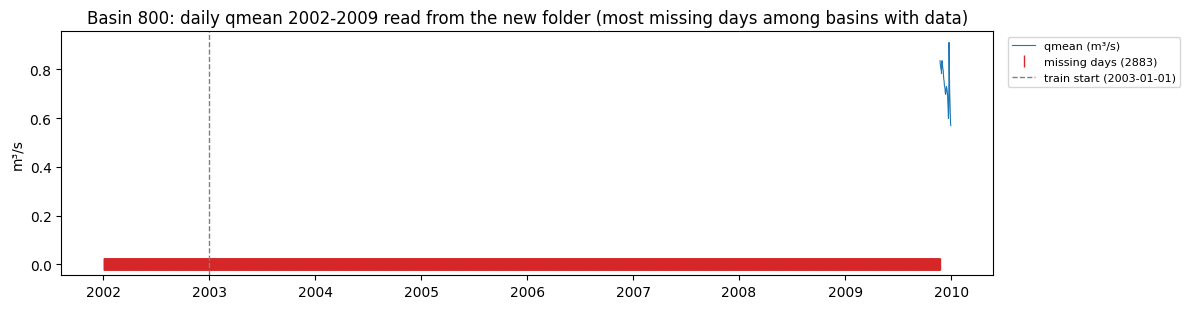

Hình: chuỗi qmean (m³/s) của lưu vực 800 đọc từ thư mục vừa dựng, khoảng tính thống kê chuẩn hóa 2002-2009; vạch đỏ ở đáy = ngày trống, đường đứt = ngày bắt đầu train. Dùng để thấy ô trống được giữ là trống.


In [4]:
# %% Phần 4 - Dựng thư mục dữ liệu có cột qmean
# Bộ nạp chỉ đọc đầu vào từ tệp khí tượng (lamah.py dòng 116-119), còn qmean nằm ở tệp trạm D_gauges, nên chép cột qmean
# (m³/s - đã kiểm ở Phần 3) sang tệp khí tượng của 451 lưu vực, ghi vào thư mục cùng tên với tác giả. Tệp trạm ghi ngày thiếu
# là -999, hàm đọc tệp trạm của thư viện đổi số âm thành ô trống (lamah.py dòng 228-229) và thống kê ở Phần 3 khớp tác giả
# theo cách đó, còn hàm đọc tệp khí tượng không đổi => phải tự đổi số âm thành ô trống khi chép, nếu không -999 thành đầu vào.
# Đọc tệp dưới dạng chữ để các cột cũ giữ nguyên từng ký tự. Thư mục thuộc tính và D_gauges không đổi nên trỏ liên kết.
# Tệp đã có (Persistence giữ lại) thì bỏ qua. Kiểm: số tệp, 3 lưu vực ngẫu nhiên, thống kê qmean đọc bằng hàm của thư viện.
# Cần chạy Phần 2, 3 trước trong phiên (dùng LAMAH_DIR, basins, scaler, start, end, QMEAN_UNIT, display, section).
import random
import time

import matplotlib.pyplot as plt
from neuralhydrology.datasetzoo.lamah import load_lamah_forcing

assert QMEAN_UNIT == "m³/s", "Chạy Phần 3 trước: chỉ dựng khi đã xác nhận tác giả dùng qmean theo m³/s"

Q_DIR = WORK_DIR / "LamaH_expanded_q_input"  # cùng tên thư mục tác giả dùng
SUB_A = "A_basins_total_upstrm"
TS_DAILY = Path("2_timeseries") / "daily"
DATE_COLS = ["YYYY", "MM", "DD"]
N_CHECK = 3
random.seed(0)


def read_text_csv(path, usecols=None):
    # Đọc CSV ';' dạng chữ (không đổi sang số), ô trống giữ là chuỗi rỗng; thêm khóa ngày dạng số để ghép.
    df = pd.read_csv(path, sep=";", dtype=str, keep_default_na=False, usecols=usecols)
    df["_key"] = pd.to_datetime(df[DATE_COLS].astype(int).rename(columns={"YYYY": "year", "MM": "month", "DD": "day"}))
    return df


def clean_qmean(ser):
    # Số âm (-999 = thiếu) => ô trống, giống load_lamah_discharge; ô trống sẵn giữ nguyên.
    return ser.where(~(pd.to_numeric(ser, errors="coerce") < 0), "")


def build_basin_file(basin):
    # Ghép qmean của tệp trạm vào tệp khí tượng theo ngày; ghi qua tệp tạm rồi đổi tên để không để lại tệp dở.
    forcing = read_text_csv(LAMAH_DIR / SUB_A / TS_DAILY / f"ID_{basin}.csv")
    gauge = read_text_csv(LAMAH_DIR / "D_gauges" / TS_DAILY / f"ID_{basin}.csv", usecols=DATE_COLS + ["qmean"])
    merged = forcing.merge(gauge[["_key", "qmean"]], on="_key", how="left").drop(columns="_key")
    merged["qmean"] = clean_qmean(merged["qmean"].fillna(""))
    dst = Q_DIR / SUB_A / TS_DAILY / f"ID_{basin}.csv"
    tmp = dst.with_suffix(".tmp")
    merged.to_csv(tmp, sep=";", index=False)
    tmp.rename(dst)


# (1) Dựng thư mục
t0 = time.time()
(Q_DIR / SUB_A / TS_DAILY).mkdir(parents=True, exist_ok=True)
for link, target in [(Q_DIR / SUB_A / "1_attributes", LAMAH_DIR / SUB_A / "1_attributes"),
                     (Q_DIR / "D_gauges", LAMAH_DIR / "D_gauges")]:
    if not (link.exists() or link.is_symlink()):
        link.symlink_to(target, target_is_directory=True)
todo = [b for b in basins if not (Q_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv").exists()]
for b in todo:
    build_basin_file(b)
files = sorted((Q_DIR / SUB_A / TS_DAILY).glob("ID_*.csv"))
size_gb = sum(f.stat().st_size for f in files) / 1e9

section("(1) Thư mục đã dựng")
display(pd.DataFrame([
    ("Thư mục", str(Q_DIR)),
    ("Tệp khí tượng có qmean", f"{len(files)} / {len(basins)} (dựng mới {len(todo)}, có sẵn {len(basins) - len(todo)})"),
    ("Dung lượng", f"{size_gb:.2f} GB"),
    ("Liên kết", "A_basins_total_upstrm/1_attributes, D_gauges => bản gốc"),
    ("Thời gian", f"{time.time() - t0:.0f} giây"),
], columns=["mục", "giá trị"]))

# (2) Kiểm 3 lưu vực ngẫu nhiên: cột cũ giữ nguyên từng ký tự, qmean trùng tệp trạm (sau khi đổi -999 thành ô trống)
rows = []
for b in random.sample(basins, N_CHECK):
    src = read_text_csv(LAMAH_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv")
    new = read_text_csv(Q_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv")
    gauge = read_text_csv(LAMAH_DIR / "D_gauges" / TS_DAILY / f"ID_{b}.csv", usecols=DATE_COLS + ["qmean"])
    same_old = new.drop(columns="qmean").equals(src)
    q = new.set_index("_key")["qmean"]
    g_raw = gauge.set_index("_key")["qmean"]
    g = clean_qmean(g_raw)
    common = q.index.intersection(g.index)
    rows.append({"lưu vực": b, "số cột": new.shape[1] - 1, "cột cũ giữ nguyên": "có" if same_old else "KHÔNG",
                 "ngày có qmean": int((q != "").sum()), "qmean trùng tệp trạm": "có" if q[common].equals(g[common]) else "KHÔNG",
                 "-999 ở tệp trạm": int((pd.to_numeric(g_raw, errors="coerce") < 0).sum()),
                 "qmean âm còn lại": int((pd.to_numeric(q, errors="coerce") < 0).sum())})
section(f"(2) Kiểm {N_CHECK} lưu vực ngẫu nhiên (số cột không tính cột khóa ngày)")
display(pd.DataFrame(rows))

# (3) Kiểm đầu cuối: đọc qmean từ thư mục mới bằng hàm đọc tệp khí tượng của thư viện, so thống kê với tệp chuẩn hóa
qmean_new = [load_lamah_forcing(Q_DIR, b, sub_dataset="lamah_a")["qmean"].loc[start:end].to_numpy() for b in basins]
arr = np.concatenate(qmean_new)
ref_mean, ref_std = float(scaler["xarray_feature_center"]["qmean"]), float(scaler["xarray_feature_scale"]["qmean"])
m, s = np.nanmean(arr), np.nanstd(arr)
section(f"(3) Kiểm đầu cuối: qmean đọc bằng load_lamah_forcing, {start.date()} - {end.date()}, {len(basins)} lưu vực")
display(pd.DataFrame([
    {"nguồn": "tệp chuẩn hóa của tác giả", "trung bình": f"{ref_mean:.4f}", "độ lệch chuẩn": f"{ref_std:.4f}", "khớp": ""},
    {"nguồn": "thư mục vừa dựng", "trung bình": f"{m:.4f}", "độ lệch chuẩn": f"{s:.4f}",
     "khớp": "có" if max(abs(m - ref_mean) / ref_mean, abs(s - ref_std) / ref_std) < MATCH_TOL else "KHÔNG"},
]))
print(f"Ô trống qmean trong khoảng trên: {np.isnan(arr).sum():,} / {arr.size:,} ngày-lưu vực ({np.isnan(arr).mean():.2%})")

# (4) Hình: chuỗi qmean 2002-2009 của lưu vực mẫu đọc từ thư mục mới, đánh dấu ngày trống
n_missing = {b: int(np.isnan(v).sum()) for b, v in zip(basins, qmean_new)}
partial = {b: n for b, n in n_missing.items() if 0 < n < len(qmean_new[0])}  # bỏ lưu vực trống toàn bộ khoảng
plot_basin = max(partial, key=partial.get) if partial else basins[0]  # lưu vực trống nhiều nhất nhưng vẫn có số đo
print(f"Lưu vực trống toàn bộ khoảng: {[b for b, n in n_missing.items() if n == len(qmean_new[0])]}")
ser = load_lamah_forcing(Q_DIR, plot_basin, sub_dataset="lamah_a")["qmean"].loc[start:end]
fig, ax = plt.subplots(figsize=(12, 3.2))
ax.plot(ser.index, ser.values, lw=0.8, color="tab:blue", label="qmean (m³/s)")
missing = ser.index[ser.isna()]
ax.plot(missing, [0] * len(missing), "|", color="tab:red", ms=8, label=f"missing days ({len(missing)})")
ax.axvline(cfg_q.train_start_date, color="gray", ls="--", lw=1, label="train start (2003-01-01)")
ax.set_title(f"Basin {plot_basin}: daily qmean 2002-2009 read from the new folder (most missing days among basins with data)")
ax.set_ylabel("m³/s")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)  # chú thích đặt ngoài vùng vẽ
plt.tight_layout()
plt.show()
caption(f"chuỗi qmean (m³/s) của lưu vực {plot_basin} đọc từ thư mục vừa dựng, khoảng tính thống kê chuẩn hóa"
        " 2002-2009; vạch đỏ ở đáy = ngày trống, đường đứt = ngày bắt đầu train. Dùng để thấy ô trống được giữ là trống.")


# Phần 5:

In [5]:
# %% Phần 5 - Chép 6 run của tác giả sang thư mục làm việc, sửa đường dẫn trong config
# /kaggle/input chỉ đọc, còn khi đánh giá thư viện ghi kết quả vào run_dir/test/ (tester.py dòng 399) => chép run sang
# WORK_DIR/a2_runs. Bỏ test/ (kết quả gốc của tác giả để nguyên ở input cho Phần 7 so), validation/, model_epoch*.pt,
# optimizer (bài đánh giá bằng best_model.pt). Config: đổi đường dẫn máy tác giả sang Kaggle; run có qmean đọc Q_DIR.
# Trước khi chép: đối chiếu NSE trung vị test có sẵn của tác giả với số trong bài. Cuối cùng dựng mô hình, nạp trọng số thử.
# Cần chạy Phần 2, 4 trước trong phiên (dùng EXP_DIR, LAMAH_DIR, Q_DIR, A2_RUNS, WORK_DIR, read_yaml, display, section).
import shutil

import torch
from ruamel.yaml import YAML
from neuralhydrology.modelzoo import get_model
from neuralhydrology.utils.config import Config

RUNS_DIR = WORK_DIR / "a2_runs"
BASIN_FILE = EXP_DIR / "basins_filtered.txt"
PAPER_TOL = 0.005  # bài làm tròn 2 chữ số => lệch tới 0,005 vẫn khớp
RUN_SHORT = {  # nhãn ở A2_RUNS => tên thư mục ngắn trong a2_runs
    "SeqLSTM có Q": "SeqLSTM_Q", "SeqLSTM không Q": "SeqLSTM_noQ", "EncDec có Q": "EncDec_Q",
    "EncDec không Q": "EncDec_noQ", "D_FC (mốc dưới)": "D_FC", "D_RA (mốc trên)": "D_RA",
}
PAPER_NSE = {  # NSE trung vị trong bài: (giá trị, vị trí)
    "SeqLSTM có Q": (0.71, "mục 3.4"), "SeqLSTM không Q": (0.63, "mục 3.2"), "EncDec có Q": (0.66, "mục 3.4"),
    "EncDec không Q": (0.57, "mục 3.2, 3.4"), "D_FC (mốc dưới)": (0.39, "Bảng F1"), "D_RA (mốc trên)": (0.69, "mục 3.4, Bảng F1"),
}
COPY_IGNORE = shutil.ignore_patterns("test", "validation", "model_epoch*.pt", "optimizer_state*")
DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"
N_CPU = os.cpu_count() or 1


def author_metrics(run_dir):
    # Bảng chỉ số test của tác giả (test/best_model/test_metrics.csv), cột NSE tên "NSE" khi chỉ có 1 nhãn (tester.py dòng 339).
    files = sorted(run_dir.rglob("test_metrics.csv"))
    if not files:
        raise FileNotFoundError(f"Không thấy test_metrics.csv trong {run_dir}")
    return pd.read_csv(files[0], dtype={"basin": str}).set_index("basin")


def nse_col(df):
    return next(c for c in df.columns if c == "NSE" or c.endswith("_NSE"))


def count_files(val):
    # Số tệp trong trường danh sách tệp; config tác giả ghi chuỗi "None" khi trống (Config._parse_config đổi thành None).
    if val is None or val == "None":
        return 0
    return len(val) if isinstance(val, list) else 1


def find_home_paths(obj, key=""):
    # Mọi giá trị chuỗi còn trỏ máy tác giả (/home/...), kể cả trong list/dict lồng nhau.
    if isinstance(obj, str):
        return [key] if obj.startswith("/home/") else []
    if isinstance(obj, dict):
        return [k for kk, v in obj.items() for k in find_home_paths(v, f"{key}.{kk}".strip("."))]
    if isinstance(obj, list):
        return [k for i, v in enumerate(obj) for k in find_home_paths(v, f"{key}[{i}]")]
    return []


# (1) Đối chiếu: NSE trung vị test có sẵn của tác giả (test_metrics.csv ở input) với số trong bài
paper_rows = []
for run, label in A2_RUNS.items():
    nse = author_metrics(EXP_DIR / run).pipe(lambda d: d[nse_col(d)])
    ref, where = PAPER_NSE[label]
    paper_rows.append({"run": RUN_SHORT[label], "thư mục": run.split("/")[-1], "NSE trung vị (tệp tác giả)": nse.median(),
                       "bài": ref, "vị trí trong bài": where, "số lưu vực": int(nse.notna().sum()),
                       "khớp": "có" if abs(nse.median() - ref) <= PAPER_TOL else "KHÔNG"})
section(f"(1) Đối chiếu run với số trong bài (khớp khi lệch <= {PAPER_TOL}, do bài làm tròn 2 chữ số)")
display(pd.DataFrame(paper_rows).style.format({"NSE trung vị (tệp tác giả)": "{:.4f}", "bài": "{:.2f}"}).hide(axis="index"))
if any(r["khớp"] != "có" for r in paper_rows):
    print("Lưu ý: có run lệch số trong bài - vẫn chép tiếp, gửi bảng này để kiểm")
runs = A2_RUNS

# (2) Chép run và sửa config
yaml_rt = YAML()  # giữ nguyên thứ tự, định dạng các trường khác
yaml_rt.width = 4096
copy_rows = []
for run, label in runs.items():
    src, dst = EXP_DIR / run, RUNS_DIR / RUN_SHORT[label]
    status = "có sẵn" if (dst / "best_model.pt").exists() else "chép mới"
    if status == "chép mới":
        shutil.rmtree(dst, ignore_errors=True)  # bỏ bản chép dở (nếu lần trước bị ngắt)
        shutil.copytree(src, dst, ignore=COPY_IGNORE)
    cfg_raw = yaml_rt.load((src / "config.yml").read_text(encoding="utf-8"))  # luôn sửa từ config gốc
    has_q = "qmean" in str([cfg_raw.get(k) for k in ("dynamic_inputs", "hindcast_inputs", "forecast_inputs")])
    author_workers = cfg_raw.get("num_workers")
    new_vals = {
        "data_dir": str(Q_DIR if has_q else LAMAH_DIR),
        "run_dir": str(dst), "train_dir": str(dst / "train_data"),
        "train_basin_file": str(BASIN_FILE), "validation_basin_file": str(BASIN_FILE), "test_basin_file": str(BASIN_FILE),
        "device": DEVICE,
    }
    if "img_log_dir" in cfg_raw:
        new_vals["img_log_dir"] = str(dst / "img_log")
    if isinstance(author_workers, int) and author_workers > N_CPU:
        new_vals["num_workers"] = N_CPU
    for k, v in new_vals.items():
        cfg_raw[k] = v
    left = find_home_paths(dict(cfg_raw))
    assert not left, f"{label}: còn trường trỏ máy tác giả {left} - dừng lại, báo kết quả"
    with open(dst / "config.yml", "w", encoding="utf-8") as f:
        yaml_rt.dump(cfg_raw, f)
    copy_rows.append({"run": RUN_SHORT[label], "nhãn": label, "mô hình": cfg_raw.get("model"),
                      "data_dir": "Q_DIR" if has_q else "LAMAH_DIR", "trạng thái": status,
                      "MB": round(sum(p.stat().st_size for p in dst.rglob("*") if p.is_file()) / 1e6, 1),
                      "num_workers": f"{author_workers} => {new_vals.get('num_workers', author_workers)}",
                      "basin id": cfg_raw.get("use_basin_id_encoding", False),
                      "tệp đặc trưng thêm": count_files(cfg_raw.get("additional_feature_files"))})
section(f"(2) Run đã chép vào {RUNS_DIR} và sửa config (device = {DEVICE}, CPU = {N_CPU})")
print("data_dir: run có qmean => thư mục Q dựng ở Phần 4, còn lại => dữ liệu gốc; num_workers: của tác giả => dùng ở Kaggle")
display(pd.DataFrame(copy_rows))

# (3) Kiểm: nạp lại config bằng thư viện, đường dẫn tồn tại, dựng mô hình và nạp best_model.pt
check_rows = []
for row in copy_rows:
    rd = RUNS_DIR / row["run"]
    cfg = Config(rd / "config.yml")
    paths = {"data_dir": cfg.data_dir, "test_basin_file": cfg.test_basin_file,
             "best_model.pt": rd / "best_model.pt", "tệp chuẩn hóa": rd / "train_data" / "train_data_scaler.yml"}
    missing = [k for k, p in paths.items() if not Path(p).exists()]
    try:
        model = get_model(cfg)
        model.load_state_dict(torch.load(rd / "best_model.pt", map_location="cpu"))
        load_ok, n_params = "có", sum(p.numel() for p in model.parameters())
    except Exception as e:  # in lỗi vào bảng để thấy hết các run, không dừng ở run đầu
        load_ok, n_params = f"LỖI: {type(e).__name__}: {str(e)[:120]}", None
    check_rows.append({"run": row["run"], "đường dẫn thiếu": ", ".join(missing) or "không",
                       "nạp trọng số": load_ok, "số tham số": f"{n_params:,}" if n_params else "-",
                       "lưu vực test": len(Path(cfg.test_basin_file).read_text().split())})
section("(3) Kiểm từng run: đường dẫn, dựng mô hình, nạp best_model.pt")
display(pd.DataFrame(check_rows))
A2_READY = all(r["đường dẫn thiếu"] == "không" and r["nạp trọng số"] == "có" for r in check_rows)
print("=> A2_READY =", A2_READY, "(sang Phần 6 khi True)")


----------------------------------------------------------------------------------------------------
(1) Đối chiếu run với số trong bài (khớp khi lệch <= 0.005, do bài làm tròn 2 chữ số)
----------------------------------------------------------------------------------------------------


run,thư mục,NSE trung vị (tệp tác giả),bài,vị trí trong bài,số lưu vực,khớp
SeqLSTM_Q,Sequential_Forecast_LSTM_RA_with_q_Simple_Embedding,0.7053,0.71,mục 3.4,450,có
SeqLSTM_noQ,Sequential_Forecast_LSTM_RA_without_q_Simple_Embedding,0.6276,0.63,mục 3.2,451,có
EncDec_Q,Encoder_Decoder_LSTM_with_q_Complex_Embedding,0.6622,0.66,mục 3.4,450,có
EncDec_noQ,Encoder_Decoder_LSTM_RA_without_q_Complex_Embedding,0.5689,0.57,"mục 3.2, 3.4",451,có
D_FC,Forecast,0.3867,0.39,Bảng F1,451,có
D_RA,Reanalysis_Simple_Embedding,0.6923,0.69,"mục 3.4, Bảng F1",451,có



----------------------------------------------------------------------------------------------------
(2) Run đã chép vào /kaggle/working/a2_runs và sửa config (device = cuda:0, CPU = 4)
----------------------------------------------------------------------------------------------------
data_dir: run có qmean => thư mục Q dựng ở Phần 4, còn lại => dữ liệu gốc; num_workers: của tác giả => dùng ở Kaggle


,run,nhãn,mô hình,data_dir,trạng thái,MB,num_workers,basin id,tệp đặc trưng thêm
0,SeqLSTM_Q,SeqLSTM có Q,sequential_forecast_lstm,Q_DIR,chép mới,0.4,20 => 4,False,0
1,SeqLSTM_noQ,SeqLSTM không Q,sequential_forecast_lstm,LAMAH_DIR,chép mới,0.4,20 => 4,False,0
2,EncDec_Q,EncDec có Q,handoff_forecast_lstm,Q_DIR,chép mới,1.4,20 => 4,False,0
3,EncDec_noQ,EncDec không Q,handoff_forecast_lstm,LAMAH_DIR,chép mới,1.4,20 => 4,False,0
4,D_FC,D_FC (mốc dưới),cudalstm,LAMAH_DIR,chép mới,0.3,20 => 4,False,0
5,D_RA,D_RA (mốc trên),cudalstm,LAMAH_DIR,chép mới,0.4,20 => 4,False,0



----------------------------------------------------------------------------------------------------
(3) Kiểm từng run: đường dẫn, dựng mô hình, nạp best_model.pt
----------------------------------------------------------------------------------------------------


,run,đường dẫn thiếu,nạp trọng số,số tham số,lưu vực test
0,SeqLSTM_Q,không,có,"84,785",451
1,SeqLSTM_noQ,không,có,"84,769",451
2,EncDec_Q,không,có,"341,436",451
3,EncDec_noQ,không,có,"341,406",451
4,D_FC,không,có,"83,713",451
5,D_RA,không,có,"84,129",451


=> A2_READY = True (sang Phần 6 khi True)


# Phần 6:

In [6]:
# %% Phần 6 - Chạy đánh giá tập test cho 6 run bằng best_model.pt
# eval_run(..., epoch="best") nạp best_model.pt (tester.py dòng 137-139), dự báo kỳ test 2014-2017 cho 451 lưu vực,
# ghi a2_runs/<run>/test/best_model/test_metrics.csv (chỉ số theo lưu vực) và test_results.p (chuỗi quan trắc, dự báo
# theo ngày - A3 dùng). Run đã có test_metrics.csv (Persistence giữ lại) thì bỏ qua. Đo thời gian từng run.
# Cần chạy Phần 5 trước trong phiên (dùng RUNS_DIR, copy_rows, A2_RUNS, RUN_SHORT, EXP_DIR, author_metrics, nse_col).
from neuralhydrology.nh_run import eval_run

assert A2_READY, "Phần 5 chưa đạt (A2_READY = False) - kiểm lại bảng (3) của Phần 5"
GPU_ID = 0 if torch.cuda.is_available() else -1  # < 0 => CPU (nh_run.py dòng 169-172)


def new_metrics_file(run_name):
    return RUNS_DIR / run_name / "test" / "best_model" / "test_metrics.csv"


eval_rows = []
for run, label in A2_RUNS.items():
    name = RUN_SHORT[label]
    status, t0 = "có sẵn", time.time()
    if not new_metrics_file(name).exists():
        print(f"\n>>> Đánh giá {name} ...")
        eval_run(run_dir=RUNS_DIR / name, period="test", epoch="best", gpu=GPU_ID)
        status = "chạy mới"
    new = pd.read_csv(new_metrics_file(name), dtype={"basin": str}).set_index("basin")
    old = author_metrics(EXP_DIR / run)
    new_nse, old_nse = new[nse_col(new)], old[nse_col(old)]
    eval_rows.append({"run": name, "trạng thái": status, "giây": round(time.time() - t0) if status == "chạy mới" else "-",
                      "lưu vực có NSE": int(new_nse.notna().sum()),
                      "NSE trung vị chạy lại": new_nse.median(), "NSE trung vị tác giả": old_nse.median(),
                      "chênh": new_nse.median() - old_nse.median()})
eval_df = pd.DataFrame(eval_rows)
eval_df["khớp"] = ["có" if abs(d) <= PAPER_TOL else "KHÔNG" for d in eval_df["chênh"]]

section(f"Kết quả đánh giá tập test (best_model.pt, {'GPU' if GPU_ID >= 0 else 'CPU'}) - so sơ bộ với kết quả có sẵn "
        f"của tác giả, khớp khi |chênh| <= {PAPER_TOL}; so từng lưu vực ở Phần 7")
display(eval_df.style.format({"NSE trung vị chạy lại": "{:.4f}", "NSE trung vị tác giả": "{:.4f}", "chênh": "{:+.4f}"})
        .hide(axis="index"))
print("Tệp kết quả:", ", ".join(str(new_metrics_file(r).parent.relative_to(WORK_DIR)) for r in eval_df["run"]))


>>> Đánh giá SeqLSTM_Q ...
# Evaluation:  61%|██████    | 275/451 [03:06<01:57,  1.50it/s]

Basin 55 All simulated values are NaN, thus metrics will be NaN, too.


# Evaluation: 100%|██████████| 451/451 [05:04<00:00,  1.48it/s]

>>> Đánh giá SeqLSTM_noQ ...
# Evaluation: 100%|██████████| 451/451 [05:03<00:00,  1.49it/s]

>>> Đánh giá EncDec_Q ...
# Evaluation:  61%|██████    | 275/451 [03:19<02:07,  1.38it/s]

Basin 55 All simulated values are NaN, thus metrics will be NaN, too.


# Evaluation: 100%|██████████| 451/451 [05:25<00:00,  1.39it/s]

>>> Đánh giá EncDec_noQ ...
# Evaluation:  88%|████████▊ | 395/451 [04:31<00:37,  1.50it/s]

...

# Evaluation:  90%|████████▉ | 405/451 [04:38<00:31,  1.48it/s]

/usr/local/lib/python3.13/dist-packages/neuralhydrology/evaluation/metrics.py:333: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r, _ = stats.pearsonr(obs.values, sim.values)


# Evaluation: 100%|██████████| 451/451 [05:10<00:00,  1.45it/s]

>>> Đánh giá D_FC ...
# Evaluation: 100%|██████████| 451/451 [02:26<00:00,  3.07it/s]

>>> Đánh giá D_RA ...
# Evaluation: 100%|██████████| 451/451 [04:22<00:00,  1.72it/s]

----------------------------------------------------------------------------------------------------
Kết quả đánh giá tập test (best_model.pt, GPU) - so sơ bộ với kết quả có sẵn của tác giả, khớp khi |chênh| <= 0.005; so từng lưu vực ở Phần 7
----------------------------------------------------------------------------------------------------


run,trạng thái,giây,lưu vực có NSE,NSE trung vị chạy lại,NSE trung vị tác giả,chênh,khớp
SeqLSTM_Q,chạy mới,305,450,0.7053,0.7053,-0.0000,có
SeqLSTM_noQ,chạy mới,303,451,0.6276,0.6276,+0.0000,có
EncDec_Q,chạy mới,325,450,0.6622,0.6622,-0.0000,có
EncDec_noQ,chạy mới,311,451,0.5689,0.5689,+0.0000,có
D_FC,chạy mới,147,451,0.3864,0.3867,-0.0002,có
D_RA,chạy mới,262,451,0.6923,0.6923,+0.0001,có


Tệp kết quả: a2_runs/SeqLSTM_Q/test/best_model, a2_runs/SeqLSTM_noQ/test/best_model, a2_runs/EncDec_Q/test/best_model, a2_runs/EncDec_noQ/test/best_model, a2_runs/D_FC/test/best_model, a2_runs/D_RA/test/best_model


# Phần 7:


----------------------------------------------------------------------------------------------------
(1) So từng lưu vực: Δ = chạy lại - tác giả (tệp test_metrics.csv), đếm lưu vực lệch > 0.001 và > 0.01
----------------------------------------------------------------------------------------------------


run,chỉ số,lưu vực chung,TB |Δ|,|Δ| lớn nhất,tại lưu vực,> 0.001,> 0.01
SeqLSTM_Q,NSE,450,2.89e-04,8.49e-02,758,3,2
SeqLSTM_Q,KGE,450,5.31e-05,3.93e-03,758,2,0
SeqLSTM_noQ,NSE,451,6.40e-05,5.60e-03,742,3,0
SeqLSTM_noQ,KGE,451,6.19e-05,1.29e-03,742,2,0
EncDec_Q,NSE,450,6.42e-05,8.13e-03,758,3,0
EncDec_Q,KGE,450,4.67e-05,5.61e-04,312,0,0
EncDec_noQ,NSE,451,5.65e-05,7.06e-04,235,0,0
EncDec_noQ,KGE,449,4.96e-05,3.33e-04,235,0,0
D_FC,NSE,451,2.23e-04,2.24e-02,758,5,2
D_FC,KGE,451,8.50e-05,1.61e-03,758,2,0



----------------------------------------------------------------------------------------------------
(2) Lưu vực không có NSE và số ngày có số đo trong kỳ test
----------------------------------------------------------------------------------------------------


,run,lưu vực,tác giả cũng thiếu,ngày có qmean (kể cả khởi động),ngày có qmax (test)
0,SeqLSTM_Q,55,có,1025 / 1825,807 / 1461
1,EncDec_Q,55,có,1025 / 1825,807 / 1461



----------------------------------------------------------------------------------------------------
(3) So chuỗi dự báo qmax_sim từng ngày (mm/ngày) với test_results.p của tác giả
----------------------------------------------------------------------------------------------------


,run,tệp tác giả,|Δ qmax_sim| lớn nhất,lưu vực so
0,SeqLSTM_Q,có,0.223776,451
1,SeqLSTM_noQ,có,0.100517,451
2,EncDec_Q,có,0.095315,451
3,EncDec_noQ,có,0.105626,451
4,D_FC,có,0.089790,451
5,D_RA,có,0.122108,451


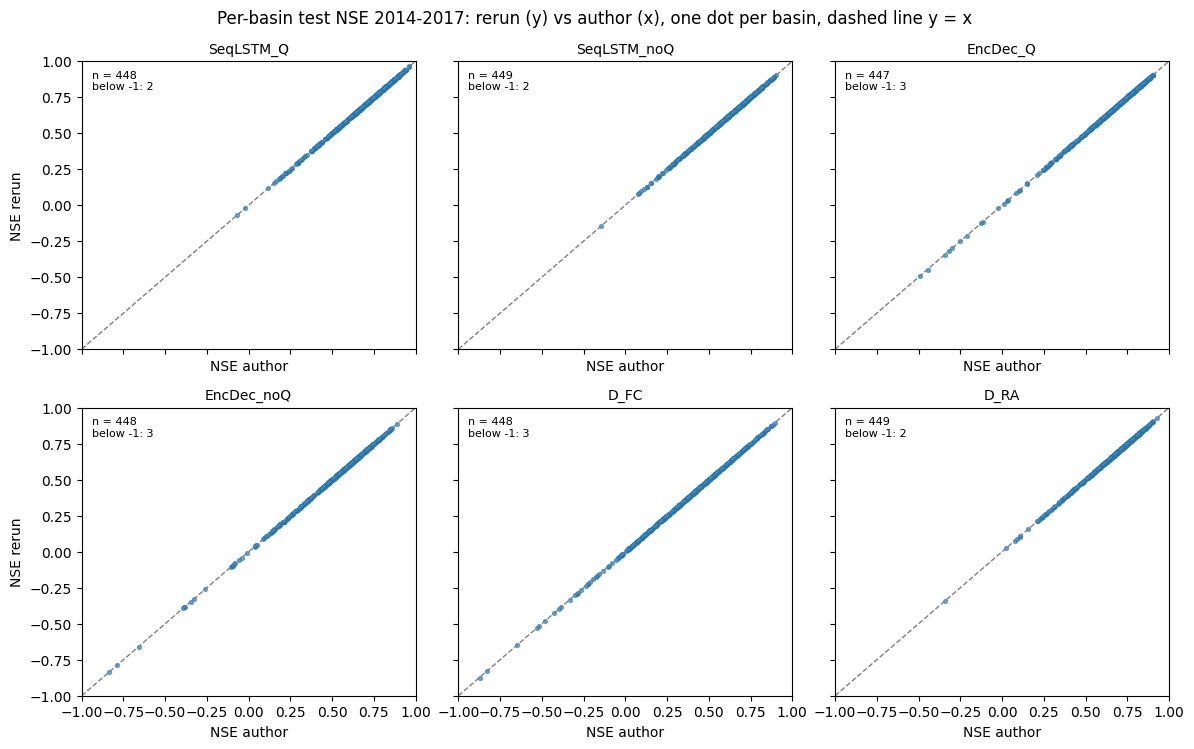

Hình: mỗi ô là một run, mỗi chấm là một lưu vực: trục ngang NSE tác giả, trục dọc NSE chạy lại. Chấm nằm trên đường chéo => hai bên trùng; lưu vực NSE < -1 nằm ngoài khung, đếm ở góc ô.


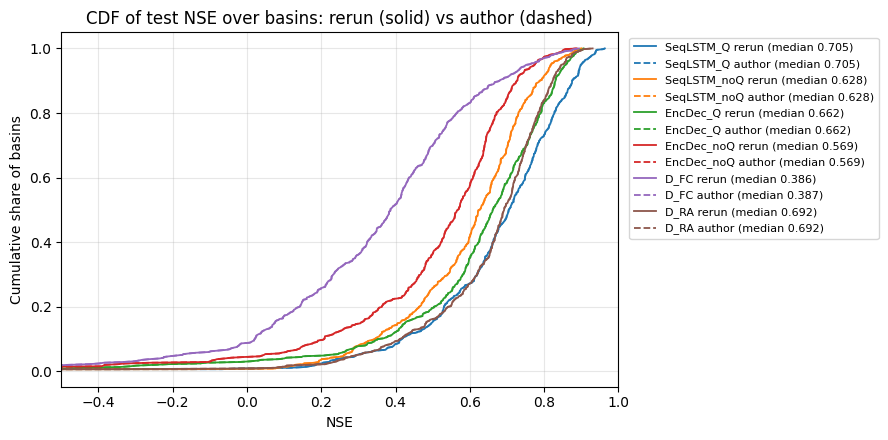

Hình: đường CDF NSE của 6 run (như Hình 7 của bài): trục dọc = tỷ lệ lưu vực có NSE nhỏ hơn giá trị trục ngang; đường càng lệch phải càng tốt. Nét liền (chạy lại) trùng nét đứt (tác giả) => tái lập khớp.

----------------------------------------------------------------------------------------------------
(5) Kết luận
----------------------------------------------------------------------------------------------------
Điều kiện: cả 6 run |Δ NSE trung vị| <= 0.005 và không lưu vực nào lệch NSE > 0.01
=> CHƯA ĐẠT theo tiêu chí sơ bộ - xem chẩn đoán và kết luận cuối ở Phần 7.2 (REPRO_OK = False)


In [7]:
# %% Phần 7.1 - So kết quả chạy lại với kết quả của tác giả theo từng lưu vực
# Cùng trọng số, cùng dữ liệu => chỉ số từng lưu vực phải gần như trùng (chỉ lệch ở chữ số cuối do GPU). (1) So mọi cột
# chỉ số của test_metrics.csv theo lưu vực; (2) lưu vực thiếu NSE ở run có Q: đếm ngày có qmean, qmax trong kỳ test;
# (3) so chuỗi dự báo từng ngày nếu tác giả có lưu test_results.p; (4) hình scatter và CDF; (5) kết luận tái lập.
# Cần chạy Phần 6 trước trong phiên (dùng eval_df, new_metrics_file, author_metrics, nse_col, Q_DIR, LAMAH_DIR...).
import pickle

REPRO_TOL = 0.01  # lệch NSE tối đa cho phép ở một lưu vực
SMALL_TOL = 0.001
NSE_CLIP = (-1, 1)  # khung trục hình scatter


def metrics_pair(run, label):
    # Bảng chỉ số chạy lại và của tác giả, ghép theo lưu vực.
    new = pd.read_csv(new_metrics_file(RUN_SHORT[label]), dtype={"basin": str}).set_index("basin")
    old = author_metrics(EXP_DIR / run)
    return new, old


# (1) So từng lưu vực, từng chỉ số
cmp_rows, pairs = [], {}
for run, label in A2_RUNS.items():
    name = RUN_SHORT[label]
    new, old = metrics_pair(run, label)
    pairs[name] = (new[nse_col(new)], old[nse_col(old)])
    for col in [c for c in new.columns if c in old.columns]:
        d = (new[col] - old[col]).dropna()
        worst = d.abs().idxmax() if len(d) else "-"
        cmp_rows.append({"run": name, "chỉ số": col, "lưu vực chung": len(d), "TB |Δ|": d.abs().mean(),
                         "|Δ| lớn nhất": d.abs().max(), "tại lưu vực": worst,
                         f"> {SMALL_TOL}": int((d.abs() > SMALL_TOL).sum()), f"> {REPRO_TOL}": int((d.abs() > REPRO_TOL).sum())})
COMPARE = pd.DataFrame(cmp_rows)
section(f"(1) So từng lưu vực: Δ = chạy lại - tác giả (tệp test_metrics.csv), đếm lưu vực lệch > {SMALL_TOL} và > {REPRO_TOL}")
display(COMPARE.style.format({"TB |Δ|": "{:.2e}", "|Δ| lớn nhất": "{:.2e}"}).hide(axis="index"))

# (2) Lưu vực thiếu NSE: đếm ngày có số đo trong kỳ test (tính cả 364 ngày khởi động cho đầu vào)
miss_rows = []
for name, (new_nse, old_nse) in pairs.items():
    for b in sorted(set(basins) - set(new_nse.dropna().index)):
        cfg_r = Config(RUNS_DIR / name / "config.yml")
        t0_in = cfg_r.test_start_date - pd.Timedelta(days=cfg_r.seq_length - 1)
        qm = load_lamah_forcing(Q_DIR, b, sub_dataset="lamah_a")["qmean"].loc[t0_in:cfg_r.test_end_date]
        qx = load_lamah_discharge(LAMAH_DIR, b, target_name="qmax")["qmax"].loc[cfg_r.test_start_date:cfg_r.test_end_date]
        miss_rows.append({"run": name, "lưu vực": b, "tác giả cũng thiếu": "có" if pd.isna(old_nse.get(b)) else "KHÔNG",
                          "ngày có qmean (kể cả khởi động)": f"{int(qm.notna().sum())} / {len(qm)}",
                          "ngày có qmax (test)": f"{int(qx.notna().sum())} / {len(qx)}"})
section("(2) Lưu vực không có NSE và số ngày có số đo trong kỳ test")
display(pd.DataFrame(miss_rows) if miss_rows else pd.DataFrame([{"kết quả": "mọi run đủ 451 lưu vực"}]))

# (3) So chuỗi dự báo từng ngày nếu tác giả có lưu test_results.p
res_rows = []
for run, label in A2_RUNS.items():
    name = RUN_SHORT[label]
    old_files = sorted((EXP_DIR / run).rglob("test_results.p"))
    if not old_files:
        res_rows.append({"run": name, "tệp tác giả": "không có", "|Δ qmax_sim| lớn nhất": None, "lưu vực so": 0})
        continue
    with open(old_files[0], "rb") as f:
        old_res = pickle.load(f)
    with open(new_metrics_file(name).parent / "test_results.p", "rb") as f:
        new_res = pickle.load(f)
    diffs = []
    for b in set(old_res) & set(new_res):
        a = new_res[b]["1D"]["xr"]["qmax_sim"].values
        o = old_res[b]["1D"]["xr"]["qmax_sim"].values
        if a.shape == o.shape:
            diffs.append(np.nanmax(np.abs(a - o)) if np.isfinite(a - o).any() else 0.0)
    res_rows.append({"run": name, "tệp tác giả": "có", "|Δ qmax_sim| lớn nhất": max(diffs) if diffs else None,
                     "lưu vực so": len(diffs)})
section("(3) So chuỗi dự báo qmax_sim từng ngày (mm/ngày) với test_results.p của tác giả")
display(pd.DataFrame(res_rows))

# (4) Hình: scatter NSE từng lưu vực và CDF
n_cols = 3
n_rows = -(-len(pairs) // n_cols)  # chia làm tròn lên
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3.8 * n_rows), sharex=True, sharey=True, squeeze=False)
axes = axes.ravel()
for ax in axes[len(pairs):]:
    ax.set_visible(False)
for ax, (name, (new_nse, old_nse)) in zip(axes, pairs.items()):
    both = pd.concat([new_nse.rename("new"), old_nse.rename("old")], axis=1).dropna()
    inside = both[(both >= NSE_CLIP[0]).all(axis=1)]
    ax.scatter(inside["old"], inside["new"], s=8, alpha=0.6, color="tab:blue")
    ax.plot(NSE_CLIP, NSE_CLIP, color="gray", lw=1, ls="--")
    ax.set_xlim(NSE_CLIP)
    ax.set_ylim(NSE_CLIP)
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("NSE author")
    ax.text(0.03, 0.97, f"n = {len(inside)}\nbelow -1: {len(both) - len(inside)}", transform=ax.transAxes,
            va="top", fontsize=8)
for ax in axes[::n_cols]:
    ax.set_ylabel("NSE rerun")
fig.suptitle("Per-basin test NSE 2014-2017: rerun (y) vs author (x), one dot per basin, dashed line y = x")
plt.tight_layout()
plt.show()
caption("mỗi ô là một run, mỗi chấm là một lưu vực: trục ngang NSE tác giả, trục dọc NSE chạy lại."
        " Chấm nằm trên đường chéo => hai bên trùng; lưu vực NSE < -1 nằm ngoài khung, đếm ở góc ô.")

fig, ax = plt.subplots(figsize=(9, 4.5))
for (name, (new_nse, old_nse)), color in zip(pairs.items(), plt.cm.tab10.colors):
    for ser, ls, tag in [(new_nse, "-", "rerun"), (old_nse, "--", "author")]:
        v = np.sort(ser.dropna().to_numpy())
        ax.plot(v, np.arange(1, len(v) + 1) / len(v), ls=ls, color=color, lw=1.3,
                label=f"{name} {tag} (median {np.median(v):.3f})")
ax.set_xlim(-0.5, 1)
ax.set_xlabel("NSE")
ax.set_ylabel("Cumulative share of basins")
ax.set_title("CDF of test NSE over basins: rerun (solid) vs author (dashed)")
ax.grid(alpha=0.3)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
plt.tight_layout()
plt.show()
caption(f"đường CDF NSE của {len(pairs)} run (như Hình 7 của bài): trục dọc = tỷ lệ lưu vực có NSE nhỏ hơn giá trị trục ngang;"
        " đường càng lệch phải càng tốt. Nét liền (chạy lại) trùng nét đứt (tác giả) => tái lập khớp.")

# (5) Kết luận
nse_rows = COMPARE[COMPARE["chỉ số"] == "NSE"]
REPRO_OK = bool((eval_df["khớp"] == "có").all() and (nse_rows[f"> {REPRO_TOL}"] == 0).all())
section("(5) Kết luận")
print(f"Điều kiện: cả {len(pairs)} run |Δ NSE trung vị| <= {PAPER_TOL} và không lưu vực nào lệch NSE > {REPRO_TOL}")
print("=> TÁI LẬP ĐẠT" if REPRO_OK else "=> CHƯA ĐẠT theo tiêu chí sơ bộ - xem chẩn đoán và kết luận cuối ở Phần 7.2",
      f"(REPRO_OK = {REPRO_OK})")


----------------------------------------------------------------------------------------------------
(1) Phân bố |Δ| dự báo qmax_sim và quan trắc qmax_obs (mm/ngày) trên mọi ngày-lưu vực
----------------------------------------------------------------------------------------------------
|Δ obs| = 0 và ô trống obs giống nhau => quan trắc trùng bản tác giả, lệch chỉ nằm ở dự báo


run,số giá trị,|Δ sim| 50%,99%,99.9%,lớn nhất,|Δ obs| lớn nhất,ô trống obs khác nhau
SeqLSTM_Q,"652,644",1.62e-04,4.99e-03,1.40e-02,2.24e-01,0.00e+00,0
SeqLSTM_noQ,"658,911",1.82e-04,5.79e-03,1.64e-02,1.01e-01,0.00e+00,0
EncDec_Q,"652,644",1.42e-04,6.69e-03,1.91e-02,9.53e-02,0.00e+00,0
EncDec_noQ,"658,911",6.94e-05,8.73e-03,2.52e-02,1.06e-01,0.00e+00,0
D_FC,"658,911",3.40e-04,1.11e-02,2.82e-02,8.98e-02,0.00e+00,0
D_RA,"658,911",9.14e-05,4.08e-03,1.10e-02,1.22e-01,0.00e+00,0



----------------------------------------------------------------------------------------------------
(2) Lưu vực lệch NSE > 0.001 (NSE = 1 - tổng bình phương sai số / (số ngày x phương sai obs): phương sai obs nhỏ => NSE nhạy)
----------------------------------------------------------------------------------------------------


run,lưu vực,NSE tác giả,NSE chạy lại,Δ NSE,phương sai obs,ngày tính,|Δ sim| lớn nhất
D_FC,242,-0.8724,-0.8750,-0.0026,0.2795,1461,0.021
EncDec_Q,312,-0.4465,-0.4479,-0.0015,1.2116,1461,0.040
EncDec_Q,324,-0.4931,-0.4941,-0.0010,0.0774,1461,0.013
D_FC,337,-0.4839,-0.4828,+0.0012,0.5060,1461,0.023
D_FC,595,-0.2821,-0.2832,-0.0011,0.9105,1461,0.018
D_FC,742,-10.7958,-10.7816,+0.0142,0.0003,1461,0.001
D_RA,742,-34.2832,-34.2845,-0.0013,0.0003,1461,0.000
SeqLSTM_Q,742,-43.9407,-43.9700,-0.0294,0.0003,1461,0.001
SeqLSTM_noQ,742,-4.2636,-4.2580,+0.0056,0.0003,1461,0.001
SeqLSTM_Q,754,-0.0197,-0.0209,-0.0013,0.0532,1461,0.002


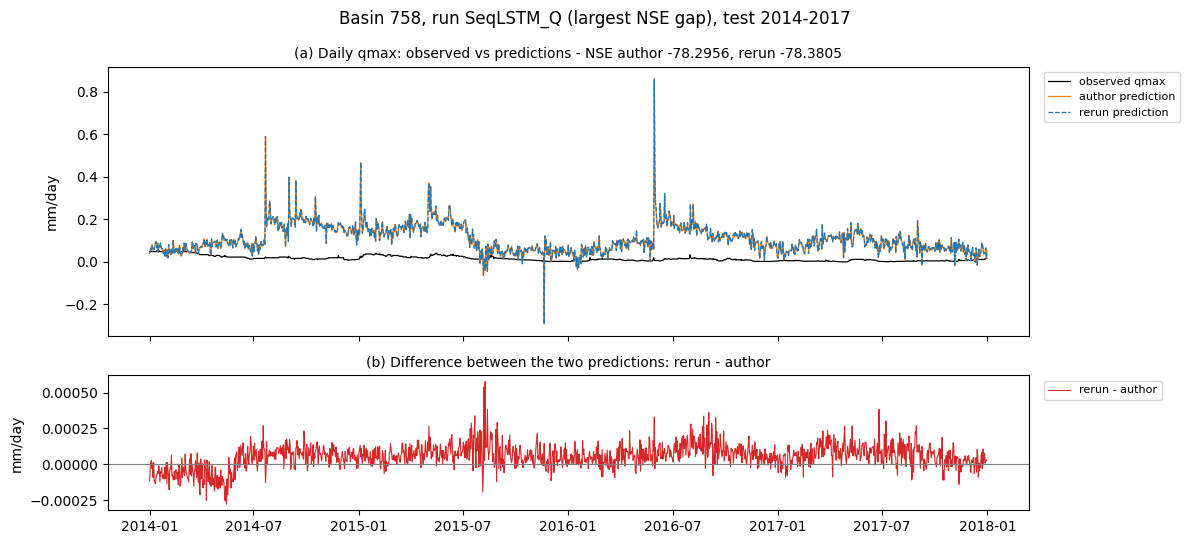

Hình: lưu vực lệch NSE nhiều nhất (758, run SeqLSTM_Q). (a) quan trắc qmax (đen), dự báo của tác giả (cam) và chạy lại (xanh đứt) theo ngày; (b) hiệu hai dự báo. Hiệu rất nhỏ so với dự báo => lệch NSE do phương sai quan trắc gần 0 khuếch đại, không phải do mô hình khác.

----------------------------------------------------------------------------------------------------
(4) Kết luận cuối
----------------------------------------------------------------------------------------------------


,điều kiện,đạt
0,quan trắc trùng tác giả ở cả 6 run (|Δ obs| = ...,có
1,|Δ NSE trung vị| <= 0.005 ở cả 6 run,có
2,|Δ qmax_sim| mức 99.9% <= 0.05 mm/ngày ở cả 6 run,có
3,mọi lưu vực lệch NSE > 0.01 đều có NSE < -1 (N...,có


Lưu vực lệch NSE > 0.01 : ['742', '758']
=> TÁI LẬP ĐẠT (REPRO_OK = True)


In [8]:
# %% Phần 7.2 - Chẩn đoán độ lệch: lưu vực lệch nhiều, quan trắc có giống không, phân bố lệch dự báo
# Chỉ đọc test_results.p của tác giả và của lần chạy lại. (1) phân bố |Δ qmax_sim| trên mọi ngày-lưu vực và |Δ qmax_obs|
# (khác 0 => dữ liệu quan trắc khác bản tác giả); (2) bảng các lưu vực lệch NSE > SMALL_TOL: NSE, phương sai quan trắc,
# số ngày tính; (3) hình chuỗi của lưu vực lệch nhiều nhất; (4) kết luận cuối, đặt lại REPRO_OK.
# Tiêu chí cuối thay tiêu chí sơ bộ của 7.1 vì NSE = 1 - SSE / (n x phương sai obs): lưu vực có phương sai obs gần 0
# (742, 758: 0,0002-0,0003) khuếch đại lệch dự báo 0,001 mm/ngày thành lệch NSE 0,01-0,08 => xét lệch ở dự báo.
# Cần chạy Phần 7.1 trước (dùng COMPARE, pairs, SMALL_TOL, eval_df...).


def load_results(path):
    with open(path, "rb") as f:
        return pickle.load(f)


def series(res, basin, var):
    # Chuỗi theo ngày của 1 biến (bước dự báo cuối), index là ngày.
    return res[basin]["1D"]["xr"][var].isel(time_step=-1).to_series()


results = {}  # run => (kết quả chạy lại, kết quả tác giả)
for run, label in A2_RUNS.items():
    name = RUN_SHORT[label]
    results[name] = (load_results(new_metrics_file(name).parent / "test_results.p"),
                     load_results(sorted((EXP_DIR / run).rglob("test_results.p"))[0]))

# (1) Phân bố lệch trên mọi ngày-lưu vực
dist_rows = []
for name, (new_res, old_res) in results.items():
    d_sim, d_obs, nan_mismatch = [], [], 0
    for b in set(new_res) & set(old_res):
        for var, store in [("qmax_sim", d_sim), ("qmax_obs", d_obs)]:
            a, o = series(new_res, b, var), series(old_res, b, var)
            a, o = a.align(o, join="outer")
            if var == "qmax_obs":
                nan_mismatch += int((a.isna() != o.isna()).sum())
            store.append((a - o).abs().dropna().to_numpy())
    d_sim, d_obs = np.concatenate(d_sim), np.concatenate(d_obs)
    q = np.quantile(d_sim, [0.5, 0.99, 0.999])
    dist_rows.append({"run": name, "số giá trị": f"{d_sim.size:,}", "|Δ sim| 50%": q[0], "99%": q[1], "99.9%": q[2],
                      "lớn nhất": d_sim.max(), "|Δ obs| lớn nhất": d_obs.max(), "ô trống obs khác nhau": nan_mismatch})
section("(1) Phân bố |Δ| dự báo qmax_sim và quan trắc qmax_obs (mm/ngày) trên mọi ngày-lưu vực")
print("|Δ obs| = 0 và ô trống obs giống nhau => quan trắc trùng bản tác giả, lệch chỉ nằm ở dự báo")
display(pd.DataFrame(dist_rows).style.format({c: "{:.2e}" for c in ["|Δ sim| 50%", "99%", "99.9%", "lớn nhất",
                                                                    "|Δ obs| lớn nhất"]}).hide(axis="index"))

# (2) Các lưu vực lệch NSE > SMALL_TOL ở ít nhất 1 run
flag_rows = []
for name, (new_nse, old_nse) in pairs.items():
    d = (new_nse - old_nse).dropna()
    new_res, old_res = results[name]
    for b in d[d.abs() > SMALL_TOL].index:
        obs = series(old_res, b, "qmax_obs")
        sim_new, sim_old = series(new_res, b, "qmax_sim"), series(old_res, b, "qmax_sim")
        valid = obs.notna() & sim_old.notna()
        flag_rows.append({"run": name, "lưu vực": b, "NSE tác giả": old_nse[b], "NSE chạy lại": new_nse[b], "Δ NSE": d[b],
                          "phương sai obs": obs[valid].var(ddof=0), "ngày tính": int(valid.sum()),
                          "|Δ sim| lớn nhất": (sim_new - sim_old).abs().max()})
flags = pd.DataFrame(flag_rows).sort_values(["lưu vực", "run"])
section(f"(2) Lưu vực lệch NSE > {SMALL_TOL} (NSE = 1 - tổng bình phương sai số / (số ngày x phương sai obs):"
        " phương sai obs nhỏ => NSE nhạy)")
display(flags.style.format({"NSE tác giả": "{:.4f}", "NSE chạy lại": "{:.4f}", "Δ NSE": "{:+.4f}",
                            "phương sai obs": "{:.4f}", "|Δ sim| lớn nhất": "{:.3f}"}).hide(axis="index"))

# (3) Hình: lưu vực lệch nhiều nhất, ở run lệch nhiều nhất
top = flags.loc[flags["Δ NSE"].abs().idxmax()]
new_res, old_res = results[top["run"]]
b = top["lưu vực"]
obs, s_old, s_new = (series(old_res, b, "qmax_obs"), series(old_res, b, "qmax_sim"), series(new_res, b, "qmax_sim"))
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
ax1.plot(obs.index, obs.values, color="black", lw=0.9, label="observed qmax")
ax1.plot(s_old.index, s_old.values, color="tab:orange", lw=0.9, label="author prediction")
ax1.plot(s_new.index, s_new.values, color="tab:blue", lw=0.9, ls="--", label="rerun prediction")
ax1.set_ylabel("mm/day")
fig.suptitle(f"Basin {b}, run {top['run']} (largest NSE gap), test 2014-2017")
ax1.set_title(f"(a) Daily qmax: observed vs predictions - NSE author {top['NSE tác giả']:.4f}, rerun {top['NSE chạy lại']:.4f}",
              fontsize=10)
ax1.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
ax2.set_title("(b) Difference between the two predictions: rerun - author", fontsize=10)
ax2.plot(s_new.index, (s_new - s_old).values, color="tab:red", lw=0.8, label="rerun - author")
ax2.axhline(0, color="gray", lw=0.8)
ax2.set_ylabel("mm/day")
ax2.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
plt.tight_layout()
plt.show()
caption(f"lưu vực lệch NSE nhiều nhất ({b}, run {top['run']}). (a) quan trắc qmax (đen), dự báo của tác giả (cam) và"
        " chạy lại (xanh đứt) theo ngày; (b) hiệu hai dự báo. Hiệu rất nhỏ so với dự báo => lệch NSE do phương sai"
        " quan trắc gần 0 khuếch đại, không phải do mô hình khác.")

# (4) Kết luận cuối
SIM_TOL = 0.05  # |Δ qmax_sim| ở mức 99,9% tối đa (mm/ngày)
dist = pd.DataFrame(dist_rows)
big = flags[flags["Δ NSE"].abs() > REPRO_TOL]
checks = {
    f"quan trắc trùng tác giả ở cả {len(pairs)} run (|Δ obs| = 0, ô trống giống nhau)":
        bool((dist["|Δ obs| lớn nhất"] == 0).all() and (dist["ô trống obs khác nhau"] == 0).all()),
    f"|Δ NSE trung vị| <= {PAPER_TOL} ở cả {len(pairs)} run": bool((eval_df["khớp"] == "có").all()),
    f"|Δ qmax_sim| mức 99.9% <= {SIM_TOL} mm/ngày ở cả {len(pairs)} run": bool((dist["99.9%"] <= SIM_TOL).all()),
    f"mọi lưu vực lệch NSE > {REPRO_TOL} đều có NSE < -1 (NSE nhạy do phương sai obs gần 0)":
        bool((big["NSE tác giả"] < -1).all()),
}
REPRO_OK = all(checks.values())
section("(4) Kết luận cuối")
display(pd.DataFrame([{"điều kiện": k, "đạt": "có" if v else "KHÔNG"} for k, v in checks.items()]))
print("Lưu vực lệch NSE >", REPRO_TOL, ":", sorted(set(big["lưu vực"])) or "không")
print("=> TÁI LẬP ĐẠT" if REPRO_OK else "=> CHƯA ĐẠT - gửi bảng để kiểm", f"(REPRO_OK = {REPRO_OK})")

# Phần 8:

In [9]:
# %% Phần 8 - Lưu kết quả cho A3, A4
# Gom vào WORK_DIR/a2_output: mỗi run test_metrics.csv, test_results.p (chuỗi quan trắc, dự báo theo ngày - A3 dùng),
# config.yml đã sửa; bảng so sánh Phần 6, 7; tệp môi trường (phiên bản thư viện, commit, GPU). Không gom thư mục Q
# (1,35 GB) vì A4 dựng lại bằng code Phần 4. Sau đó Save Version rồi tạo Kaggle Dataset từ output notebook.
# Cần chạy Phần 7 trước trong phiên (dùng eval_df, COMPARE, REPRO_OK, RUNS_DIR, A2_RUNS, RUN_SHORT).
import json
import platform
import sys
from importlib import metadata

OUT_DIR = WORK_DIR / "a2_output"
RUN_FILES = ["test/best_model/test_metrics.csv", "test/best_model/test_results.p", "config.yml"]
ENV_LIBS = ["neuralhydrology", "torch", "numpy", "pandas", "xarray", "scipy", "numba", "ruamel.yaml"]

if not REPRO_OK:
    print("Lưu ý: Phần 7 chưa đạt (REPRO_OK = False) - vẫn lưu để xem lại, nhưng chưa dùng cho A3")

# (1) Chép tệp của từng run
file_rows = []
for label in A2_RUNS.values():
    name = RUN_SHORT[label]
    for rel in RUN_FILES:
        src, dst = RUNS_DIR / name / rel, OUT_DIR / "runs" / name / Path(rel).name
        dst.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(src, dst)
        file_rows.append({"run": name, "tệp": dst.name, "KB": round(dst.stat().st_size / 1e3, 1)})

# (2) Bảng so sánh và môi trường
eval_df.to_csv(OUT_DIR / "eval_summary.csv", index=False)
COMPARE.to_csv(OUT_DIR / "compare_per_basin.csv", index=False)
try:
    nh_commit = json.loads(metadata.distribution("neuralhydrology").read_text("direct_url.json"))["vcs_info"]["commit_id"]
except Exception:  # cài không qua git => không có direct_url.json
    nh_commit = "không rõ"
env = {
    "python": sys.version.split()[0], "platform": platform.platform(),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
    "neuralhydrology_commit": nh_commit,
    "libs": {lib: metadata.version(lib) for lib in ENV_LIBS},
    "repro_ok": REPRO_OK,
    "runs": {RUN_SHORT[label]: run for run, label in A2_RUNS.items()},
    "q_dir_note": "LamaH_expanded_q_input dựng lại bằng Phần 4 (qmean m³/s từ D_gauges, số âm => trống)",
}
(OUT_DIR / "environment.json").write_text(json.dumps(env, ensure_ascii=False, indent=2), encoding="utf-8")

section(f"(1) Tệp đã lưu vào {OUT_DIR}")
display(pd.DataFrame(file_rows).pivot(index="run", columns="tệp", values="KB").add_suffix(" (KB)"))
print("Thêm: eval_summary.csv, compare_per_basin.csv, environment.json")
section("(2) Môi trường")
display(pd.DataFrame([(k, v) for k, v in env.items() if k not in ("libs", "runs")]
                     + [(f"phiên bản {k}", v) for k, v in env["libs"].items()], columns=["mục", "giá trị"]))
print("Việc tiếp: Save Version kiểu Save & Run All (chạy lại cả notebook) => mở bản đã lưu => Output => New Dataset,"
      " tên biascast-a2-reproduce (chỉ cần thư mục a2_output)")



----------------------------------------------------------------------------------------------------
(1) Tệp đã lưu vào /kaggle/working/a2_output
----------------------------------------------------------------------------------------------------


tệp,config.yml (KB),test_metrics.csv (KB),test_results.p (KB)
run,,,
D_FC,2.5,19.2,16177.8
D_RA,3.0,18.9,16177.8
EncDec_Q,3.9,18.9,16177.8
EncDec_noQ,3.9,18.9,16177.8
SeqLSTM_Q,3.8,18.8,16177.8
SeqLSTM_noQ,3.8,18.9,16177.8


Thêm: eval_summary.csv, compare_per_basin.csv, environment.json

----------------------------------------------------------------------------------------------------
(2) Môi trường
----------------------------------------------------------------------------------------------------


,mục,giá trị
0,python,3.13.15
1,platform,Linux-6.18.48+-x86_64-with-glibc2.39
2,gpu,Tesla T4
3,neuralhydrology_commit,dda45fcf19ee7ffd481b9d192778539df46fb074
4,repro_ok,True
5,q_dir_note,LamaH_expanded_q_input dựng lại bằng Phần 4 (q...
6,phiên bản neuralhydrology,1.12.0
7,phiên bản torch,2.11.0+cu128
8,phiên bản numpy,2.1.3
9,phiên bản pandas,2.3.3


Việc tiếp: Save Version kiểu Save & Run All (chạy lại cả notebook) => mở bản đã lưu => Output => New Dataset, tên biascast-a2-reproduce (chỉ cần thư mục a2_output)
